---
## Task 3 - Country-Wise Netflix Content Analysis
---

### Extracting and cleaning country information

In [1]:
#Loading the dataset
import pandas as pd
df= pd.read_csv('cleaned_dataset.csv')
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   show_id         8790 non-null   str  
 1   type            8790 non-null   str  
 2   title           8790 non-null   str  
 3   director        6202 non-null   str  
 4   country         8503 non-null   str  
 5   date_added      8790 non-null   str  
 6   release_year    8790 non-null   int64
 7   rating          8790 non-null   str  
 8   duration        8790 non-null   str  
 9   listed_in       8790 non-null   str  
 10  duration_value  8790 non-null   int64
 11  duration_unit   8790 non-null   str  
dtypes: int64(2), str(10)
memory usage: 1.7 MB


In [3]:
#Normalizing whitespace and case before filtering
country = df["country"].astype("string").str.strip()
missing = country.str.casefold().isin(["", "nan", "not given"])

#Filtering out missing values
df_country = df.loc[country.notna() & ~missing].copy()
df_country["country"] = country.loc[df_country.index]

#Splitting multi-country listings into individual rows
df_country_split = df_country.assign(
    country=df_country["country"].str.split(r",\s*")
).explode("country")

df_country_split["country"] = df_country_split["country"].str.strip()

#Checking unique countries count
print(f"Total Unique Countries: {df_country_split['country'].nunique()}")

Total Unique Countries: 85


* Splitting multi-country co-producations yielded a total of 86 unique countries represented in the Netflix Library.

* Normalizing multi-country strings ensured that international co-productions are accurately counted towards each other contributing rather than being misclassified.

* Stripping extra whitespace and dropping missing values standerdized the country entries providing a clean base for accurate aggregation and ranking.


### Calculating Content Count by Country

In [5]:
top_countries = df_country_split['country'].value_counts().head(15)

# Displaying top 15 content producing countries as a DataFrame
df_top15 = pd.DataFrame({
    'Country': top_countries.index,
    'Total_titles': top_countries.values
}).reset_index(drop=True)
df_top15

,Country,Total_titles
0,United States,3240
1,India,1057
2,United Kingdom,638
3,Pakistan,421
4,Canada,271
5,Japan,259
6,South Korea,214
7,France,213
8,Spain,182
9,Mexico,138


The United States dominates the Netflix Library with 3,240 titles, producing more than three times th econtent of second-place India(1,057 titles). Overall, the top 15 content-producing countries highlight a strong resilience on North American, European, African and Asian markets to drive global catalog diversity.

### Creating Charts and Rankings

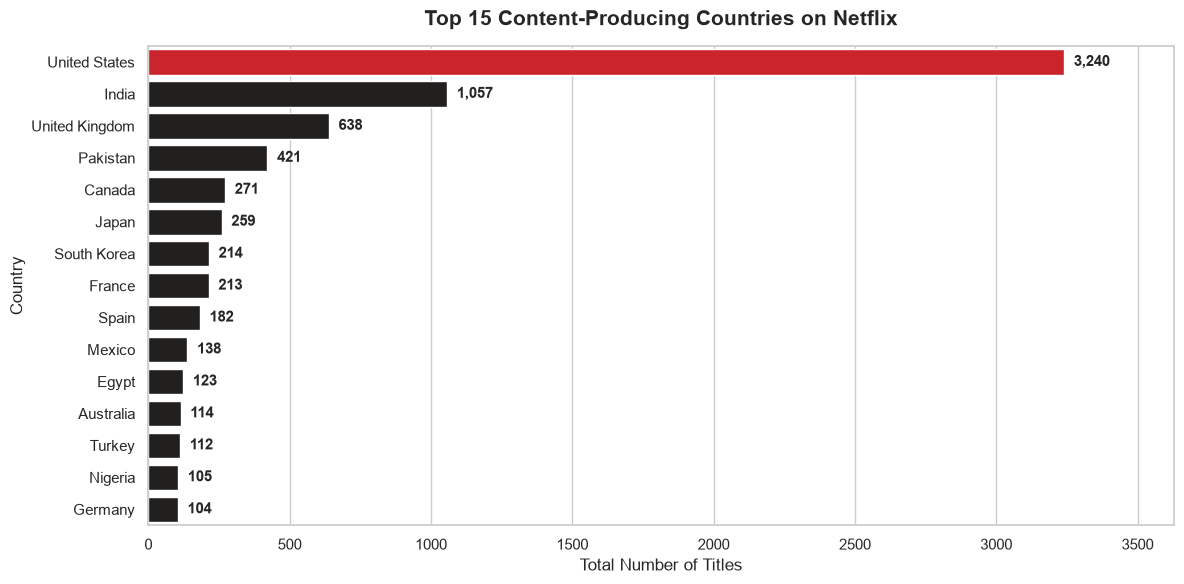

In [6]:
# Importing the matplotlib and seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# Setting figure size and style
plt.figure(figsize=(12,6))
sns.set_theme(style='whitegrid')

# Defining color palette
colors = ['#E50914'] + ['#221F1F'] * 14

# Creating the horizontal bar chart
ax = sns.barplot(
    data=df_top15,
    x='Total_titles',
    y='Country',
    hue='Country',
    palette=colors,
    legend=False
)

# Titles and labels
plt.title('Top 15 Content-Producing Countries on Netflix', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Total Number of Titles', fontsize=12)
plt.ylabel('Country', fontsize=12)

#Adding value annotations at the end of each bar
for p in ax.patches:
  width = p.get_width()
  ax.annotate(f'{int(width):,}',
              (width, p.get_y() + p.get_height() / 2.),
              ha='left', va='center',
              fontsize=11, fontweight='bold',
              xytext=(7, 0), textcoords='offset points')

# Adjusting x-axis limit to give room for labels
plt.xlim(0, df_top15['Total_titles'].max() * 1.12)

#Displaying the charts
plt.tight_layout()
plt.show()


### Key Business Insights
* **North American Dominance** - The United States leads Netflix's catalog with 3,240 titles, accounting for nearly 38% of all localized content. This reflects Netflix's historical roots and strong ties to Hollywood production hubs.

* **Growth in Asian & Regional Markets** - India ranks second globally with 1,057 titles, driven by subscriber expansion and heavy investments in regional Hindi and South Indian cinema. Japan(259) and South Korea(214) highlight Netflix's strategic focus on high-demand niche genres like Anime and K-Dramas for global export.

* **Global Content Strategy** - European markets(UK, France, Spain) along with Latin America(Mexico), North America(Canada) and Africa(Egypt, Nigeria) round out the top 15, demonstrating a balanced mix of localized original programming and cross-border licensing